# Ship Type Classification Using MobileNetV2

**Project:** Fine-Grained Ship Classification from Remote-Sensing Images  
**Dataset:** FGSC-23 (23 categories; verify the exact dataset version and extracted contents before reporting sample counts)  
**Model:** Transfer learning and class-weighted fine-tuning with MobileNetV2  
**Environment:** Google Colab / Jupyter Notebook

## Project overview

This notebook builds one end-to-end ship image classification pipeline using MobileNetV2 only. It covers dataset upload and extraction, image inspection, cleaning, train/validation/test splitting, preprocessing, augmentation, model training, fine-tuning, class weighting, evaluation, saving the model, and predicting an uploaded image.

**Important label note:** The extracted dataset uses numeric folder names. The model therefore predicts labels such as `Class 4`; it does not know the human-readable ship-type name unless the official folder-to-category mapping is independently verified. This notebook deliberately does not invent that mapping.

## 1. Install and import libraries

Run this notebook in Google Colab. TensorFlow is used for MobileNetV2, while scikit-learn handles the stratified data split and evaluation metrics.

In [6]:
!pip -q install tensorflow scikit-learn pandas pillow matplotlib

import os
import json
import time
import zipfile
import hashlib
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import drive, files

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Connect Google Drive and create project folders

The ZIP dataset will be uploaded into `raw/` and extracted into `dataset/`. Processed split files, model checkpoints, and evaluation outputs are stored separately.

In [7]:
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Ship_Classification")
RAW_DIR = PROJECT_DIR / "raw"
EXTRACT_DIR = PROJECT_DIR / "dataset"
PROCESSED_DIR = PROJECT_DIR / "processed"
MODEL_DIR = PROJECT_DIR / "models"
EVALUATION_DIR = PROJECT_DIR / "evaluation"

for folder in [RAW_DIR, EXTRACT_DIR, PROCESSED_DIR, MODEL_DIR, EVALUATION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/Ship_Classification


## 3. Upload the dataset ZIP

Upload the FGSC-23 archive you downloaded. If it is already in the `raw/` folder, this cell will use the existing ZIP instead.

In [8]:
zip_files = list(RAW_DIR.glob("*.zip"))

if not zip_files:
    uploaded = files.upload()
    for filename, content in uploaded.items():
        if filename.lower().endswith(".zip"):
            destination = RAW_DIR / Path(filename).name
            with open(destination, "wb") as f:
                f.write(content)

zip_files = list(RAW_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        f"No ZIP file found in {RAW_DIR}. Upload the FGSC-23 ZIP archive."
    )

print("ZIP files found:")
for i, path in enumerate(zip_files):
    print(i, path.name)

ZIP files found:
0 FGSC-23.zip


## 4. Extract the dataset

The first ZIP file found in `raw/` is selected. The archive paths are checked before extraction to prevent writing files outside the dataset directory.

In [9]:
ZIP_PATH = zip_files[0]
print("Selected archive:", ZIP_PATH.name)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        target = (EXTRACT_DIR / member.filename).resolve()
        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError(f"Unsafe archive path: {member.filename}")
    archive.extractall(EXTRACT_DIR)

print("Extraction complete.")
print("Dataset location:", EXTRACT_DIR)

Selected archive: FGSC-23.zip
Extraction complete.
Dataset location: /content/drive/MyDrive/Ship_Classification/dataset


## 5. Discover image files and inspect the folder structure

Each image's immediate parent folder is treated as its class label. This matches the numeric-folder structure used in the original project.

In [10]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

image_files = [
    path for path in EXTRACT_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
]

if not image_files:
    raise ValueError("No image files found. Check the ZIP contents and extraction path.")

folder_counts = Counter(path.parent.name for path in image_files)

print("Total image files discovered:", len(image_files))
print("Potential class folders:", len(folder_counts))
for label, count in sorted(folder_counts.items()):
    print(f"Folder {label}: {count} images")

Total image files discovered: 4080
Potential class folders: 23
Folder 0: 484 images
Folder 1: 166 images
Folder 10: 238 images
Folder 11: 27 images
Folder 12: 143 images
Folder 13: 225 images
Folder 14: 100 images
Folder 15: 72 images
Folder 16: 120 images
Folder 17: 343 images
Folder 18: 165 images
Folder 19: 102 images
Folder 2: 542 images
Folder 20: 88 images
Folder 21: 94 images
Folder 22: 54 images
Folder 3: 108 images
Folder 4: 295 images
Folder 5: 90 images
Folder 6: 293 images
Folder 7: 88 images
Folder 8: 154 images
Folder 9: 89 images


## 6. Visualize sample images

Inspecting random samples helps confirm that the archive contains the expected ship imagery and that the folder labels are plausible.

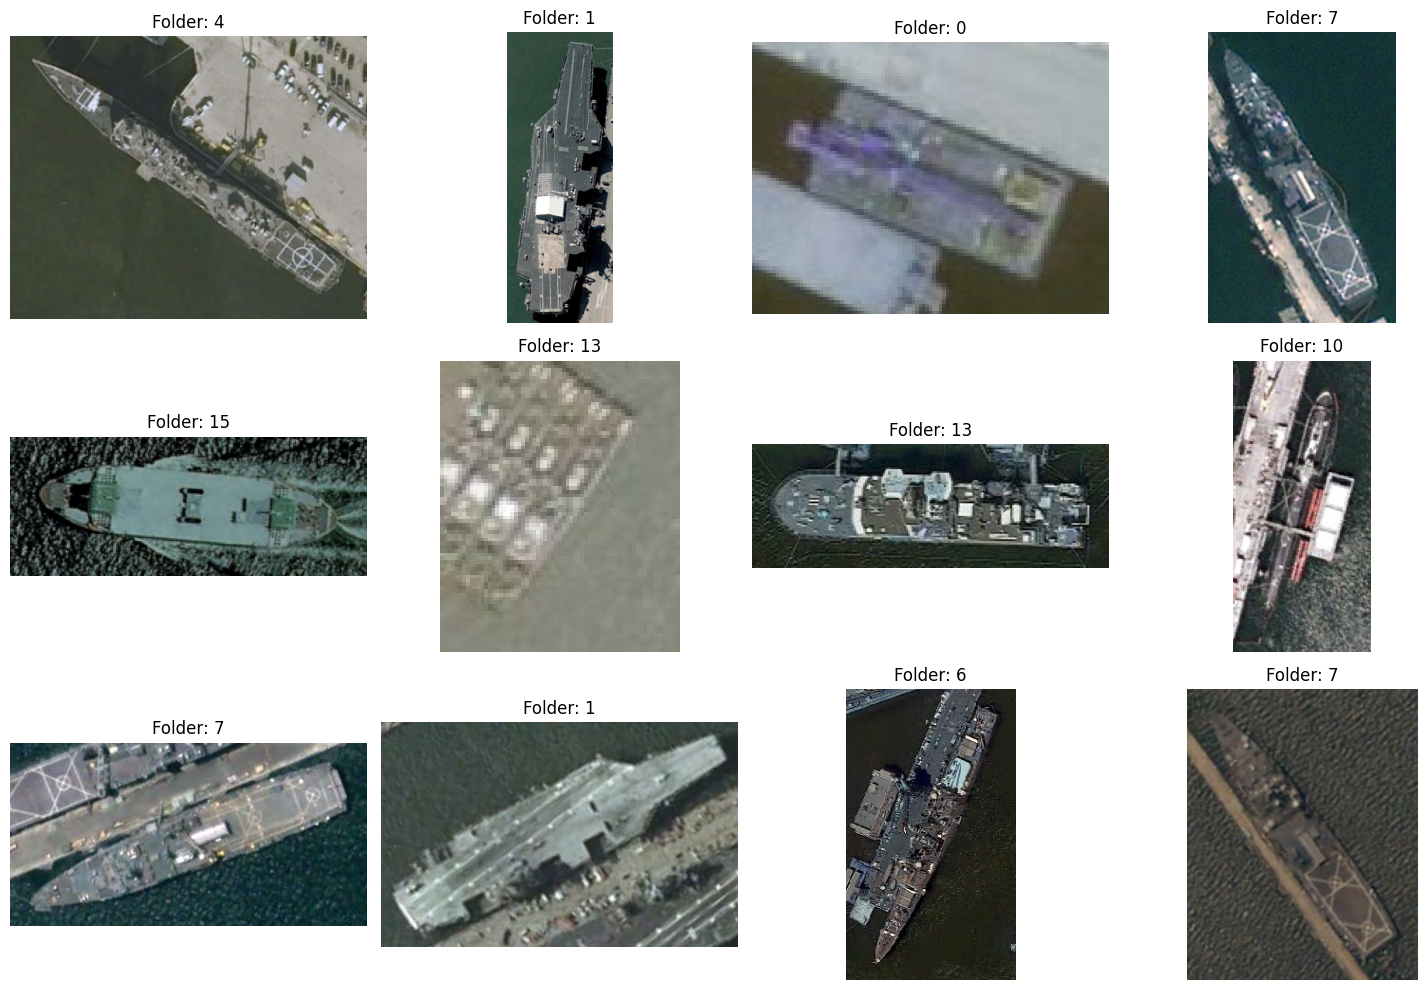

In [11]:
sample_paths = random.sample(image_files, min(12, len(image_files)))

plt.figure(figsize=(15, 10))
for i, image_path in enumerate(sample_paths, start=1):
    with Image.open(image_path) as img:
        image = img.convert("RGB")
    plt.subplot(3, 4, i)
    plt.imshow(image)
    plt.title(f"Folder: {image_path.parent.name}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Build an image inventory

Record each readable image's path, filename, folder label, dimensions, format, color mode, and file size. Images that cannot be opened are skipped here and reported during cleaning.

In [12]:
records = []

for image_path in image_files:
    try:
        with Image.open(image_path) as img:
            width, height = img.size
            records.append({
                "image_path": str(image_path),
                "file_name": image_path.name,
                "folder_label": str(image_path.parent.name),
                "width": width,
                "height": height,
                "format": img.format,
                "mode": img.mode,
                "file_size_kb": round(image_path.stat().st_size / 1024, 2)
            })
    except Exception as error:
        print("Unreadable image:", image_path, "|", error)

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No readable images were found.")

print("Readable images:", len(df))
display(df.head())
display(df[["width", "height", "file_size_kb"]].describe())

Readable images: 4080


,image_path,file_name,folder_label,width,height,format,mode,file_size_kb
0,/content/drive/MyDrive/Ship_Classification/dat...,0_10_46_13334.jpg,0,126,130,JPEG,RGB,13.92
1,/content/drive/MyDrive/Ship_Classification/dat...,0_11_166_13300.jpg,0,187,75,JPEG,RGB,7.13
2,/content/drive/MyDrive/Ship_Classification/dat...,0_12_67_13281.jpg,0,133,255,JPEG,RGB,16.93
3,/content/drive/MyDrive/Ship_Classification/dat...,0_1_103_13225.jpg,0,70,89,JPEG,RGB,3.32
4,/content/drive/MyDrive/Ship_Classification/dat...,0_1_107_13094.jpg,0,95,122,JPEG,RGB,6.21


,width,height,file_size_kb
count,4080.000000,4080.000000,4080.000000
mean,207.160539,217.879167,23.720118
std,145.239706,142.499343,25.247525
min,29.000000,32.000000,1.600000
25%,92.000000,98.000000,5.007500
50%,159.000000,182.000000,16.450000
75%,298.250000,316.000000,32.435000
max,831.000000,786.000000,205.800000


## 8. Explore class distribution and image dimensions

The class distribution shows whether some ship categories have fewer training examples. This matters because imbalanced classes can cause a classifier to favor more frequent categories.

Detected classes: 23


,Image Count
folder_label,
0,484
1,166
10,238
11,27
12,143
13,225
14,100
15,72
16,120


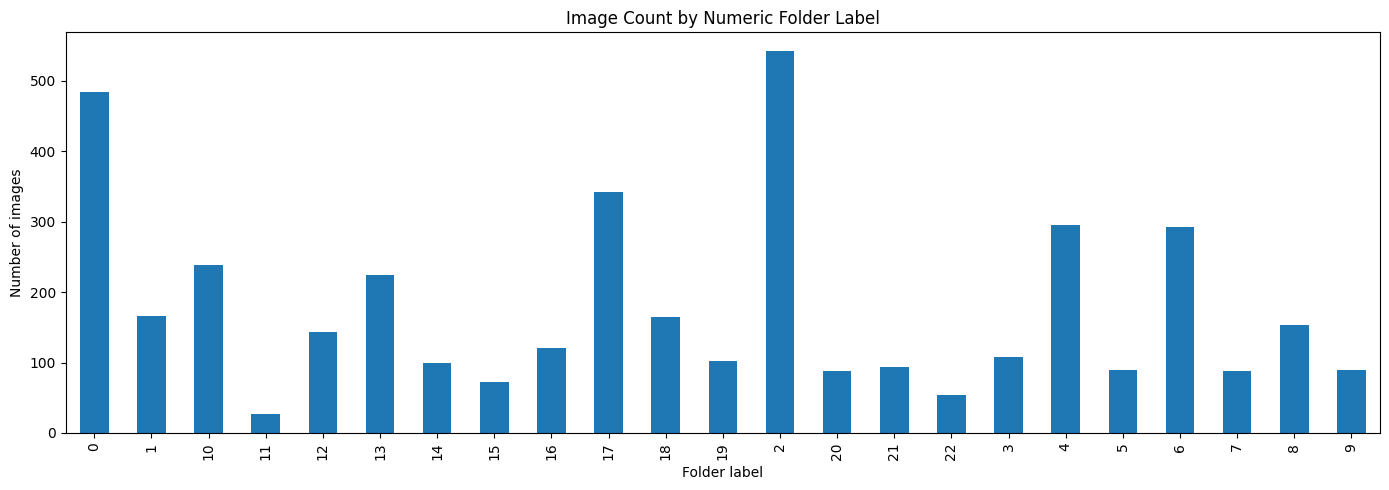

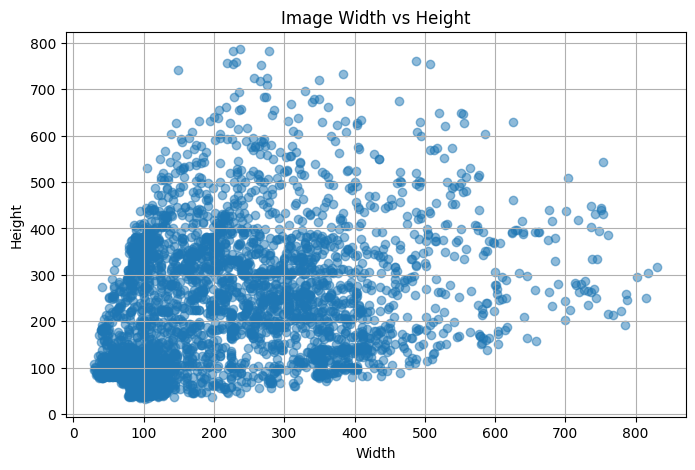

In [13]:
class_distribution = df["folder_label"].value_counts().sort_index()

print("Detected classes:", len(class_distribution))
display(class_distribution.to_frame("Image Count"))

plt.figure(figsize=(14, 5))
class_distribution.plot(kind="bar")
plt.title("Image Count by Numeric Folder Label")
plt.xlabel("Folder label")
plt.ylabel("Number of images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["width"], df["height"], alpha=0.5)
plt.title("Image Width vs Height")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid(True)
plt.show()

## 9. Remove corrupted images and exact duplicates

First verify that each image can be fully decoded. Then remove exact duplicate files using SHA-256 hashes. This prevents identical files from appearing in multiple dataset splits.

In [14]:
clean_paths = []
corrupted_records = []

for path in df["image_path"]:
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            img.load()
        clean_paths.append(path)
    except Exception as error:
        corrupted_records.append({"image_path": path, "error": str(error)})

clean_df = df[df["image_path"].isin(clean_paths)].copy()

print("Images before validation:", len(df))
print("Images after corrupted-file removal:", len(clean_df))
print("Corrupted images:", len(corrupted_records))

hashes_seen = set()
unique_indices = []
duplicate_count = 0

for idx, row in clean_df.iterrows():
    with open(row["image_path"], "rb") as f:
        digest = hashlib.sha256(f.read()).hexdigest()

    if digest not in hashes_seen:
        hashes_seen.add(digest)
        unique_indices.append(idx)
    else:
        duplicate_count += 1

clean_df = clean_df.loc[unique_indices].reset_index(drop=True)

print("Exact duplicates removed:", duplicate_count)
print("Final unique images:", len(clean_df))

if clean_df.empty:
    raise ValueError("No images remain after cleaning.")

Images before validation: 4080
Images after corrupted-file removal: 4080
Corrupted images: 0
Exact duplicates removed: 5
Final unique images: 4075


## 10. Encode class labels

The model requires integer labels. Folder names are sorted lexicographically, matching the original notebook's mapping procedure. For example, string sorting places `"10"` before `"2"`. The saved mapping preserves this exact relationship.

In [15]:
classes = sorted(clean_df["folder_label"].astype(str).unique())

class_to_index = {class_name: index for index, class_name in enumerate(classes)}
index_to_class = {index: class_name for class_name, index in class_to_index.items()}

clean_df["folder_label"] = clean_df["folder_label"].astype(str)
clean_df["label"] = clean_df["folder_label"].map(class_to_index).astype("int32")

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print("Class-to-index mapping:")
print(class_to_index)

if NUM_CLASSES != 23:
    print(f"WARNING: Expected 23 classes for FGSC-23, but found {NUM_CLASSES}. Check the extracted dataset.")

Number of classes: 23
Class-to-index mapping:
{'0': 0, '1': 1, '10': 2, '11': 3, '12': 4, '13': 5, '14': 6, '15': 7, '16': 8, '17': 9, '18': 10, '19': 11, '2': 12, '20': 13, '21': 14, '22': 15, '3': 16, '4': 17, '5': 18, '6': 19, '7': 20, '8': 21, '9': 22}


## 11. Split into training, validation, and test sets

The split is stratified so that each class is represented proportionally across the three sets:
- 70% training
- 15% validation
- 15% testing

The test set is held back for final evaluation and should not be used to tune the model.

In [16]:
train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.30,
    stratify=clean_df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).fillna(0).astype(int).sort_index()

display(split_counts)

Training images: 2852
Validation images: 611
Testing images: 612


,Train,Validation,Test
label,,,
0,339,72,73
1,116,25,25
2,167,35,36
3,19,4,4
4,100,21,22
5,157,34,34
6,68,15,14
7,50,11,11
8,84,18,18


## 12. Save split metadata and class mapping

These CSV and JSON files make the data split reproducible and allow the prediction system to translate model output indexes back to the original numeric folder labels.

In [17]:
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)

with open(PROCESSED_DIR / "class_mapping.json", "w") as f:
    json.dump({
        "class_to_index": class_to_index,
        "index_to_class": {str(k): v for k, v in index_to_class.items()}
    }, f, indent=4)

print("Split metadata and class mapping saved to:", PROCESSED_DIR)

Split metadata and class mapping saved to: /content/drive/MyDrive/Ship_Classification/processed


## 13. Configure TensorFlow and load the split metadata

Images are resized to 224 × 224 pixels and processed in batches of 32. MobileNetV2 expects three-channel RGB images.

In [18]:
AUTOTUNE = tf.data.AUTOTUNE
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Reload saved metadata to make the training stage self-contained.
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

with open(PROCESSED_DIR / "class_mapping.json", "r") as f:
    mapping_data = json.load(f)

class_to_index = mapping_data["class_to_index"]
index_to_class = {int(k): str(v) for k, v in mapping_data["index_to_class"].items()}
NUM_CLASSES = len(class_to_index)

print("Classes:", NUM_CLASSES)
print("Train / validation / test:", len(train_df), len(val_df), len(test_df))

Classes: 23
Train / validation / test: 2852 611 612


## 14. Define image preprocessing

Each image is decoded as RGB, resized to 224 × 224, converted to `float32`, and scaled from pixel values in `[0, 255]` to `[0, 1]`. The MobileNetV2 model below then rescales inputs to `[-1, 1]` internally.

In [19]:
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.cast(label, tf.int32)
    return image, label

## 15. Create efficient TensorFlow datasets

The training dataset is shuffled. Validation and test datasets are not shuffled, which keeps their prediction order aligned with the corresponding dataframes.

In [20]:
def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created.")

TensorFlow datasets created.


## 16. Define data augmentation

Random horizontal flips, rotations, zoom, and contrast changes increase training variety. Augmentation is active only during training; validation and test images remain unchanged.

In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


## 17. Inspect preprocessed batches and augmented examples

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0
Label range: 0 to 20


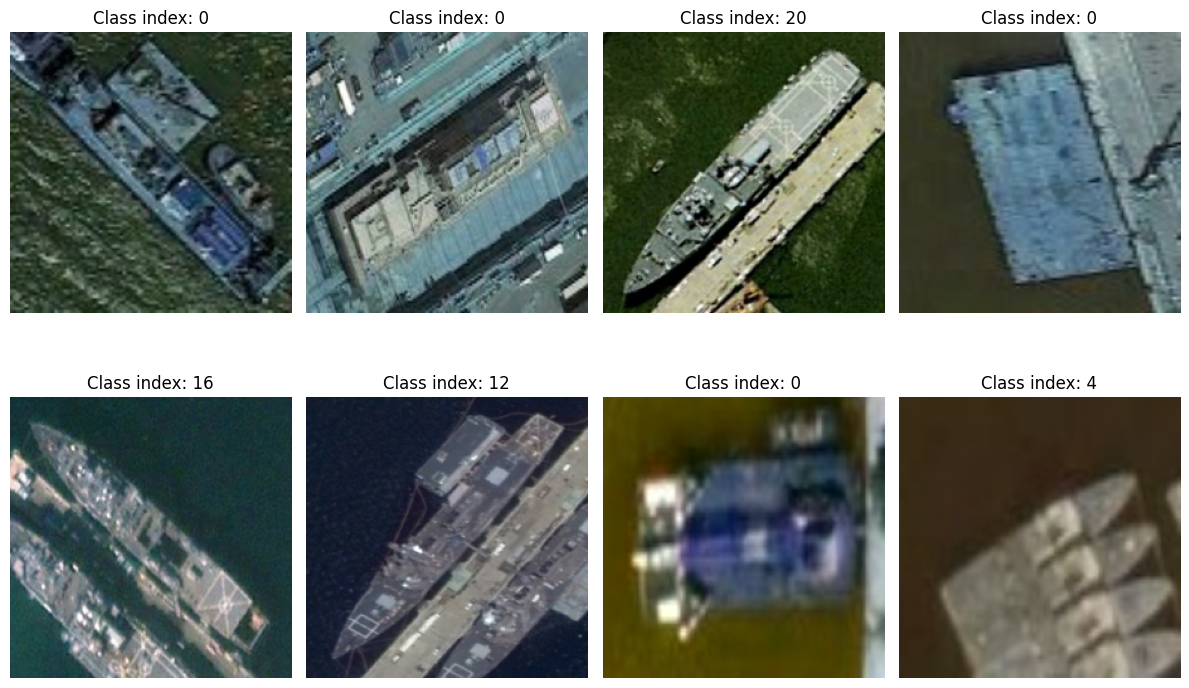

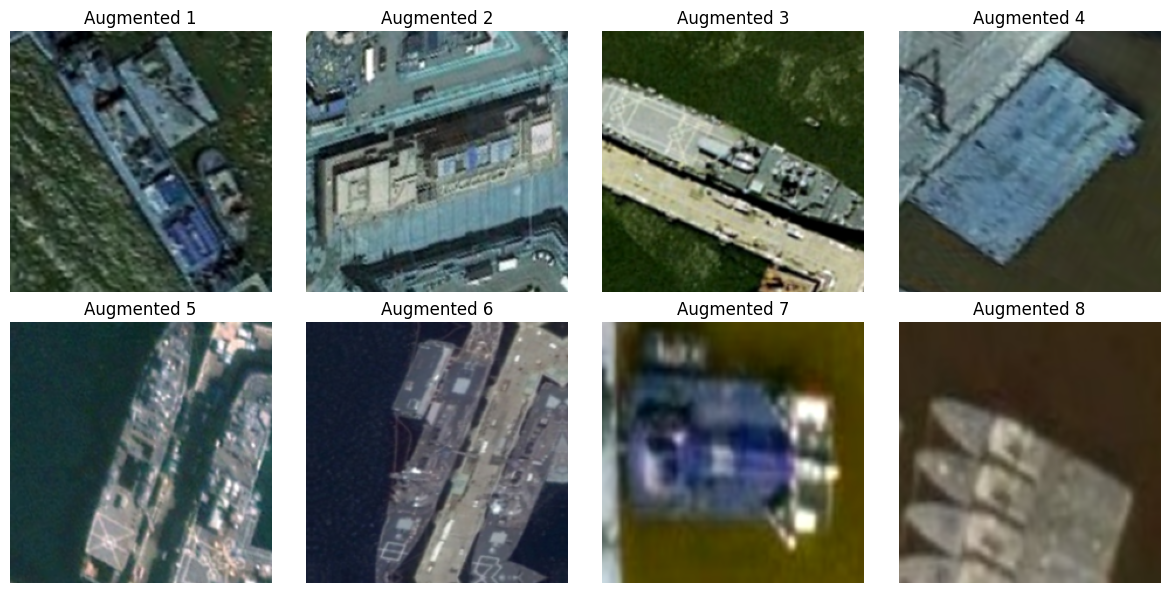

In [22]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("Label range:", int(tf.reduce_min(labels)), "to", int(tf.reduce_max(labels)))

plt.figure(figsize=(12, 8))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(f"Class index: {int(labels[i])}")
    plt.axis("off")
plt.tight_layout()
plt.show()

augmented = data_augmentation(images[:8], training=True)
plt.figure(figsize=(12, 6))
for i in range(min(8, len(augmented))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.clip_by_value(augmented[i], 0, 1).numpy())
    plt.title(f"Augmented {i+1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 18. Build the MobileNetV2 transfer-learning model

MobileNetV2 is initialized with ImageNet weights. Its pretrained convolutional layers are initially frozen, and a new classification head is trained for the dataset's 23 classes.

The model applies augmentation and rescales `[0, 1]` images to `[-1, 1]`, which is the expected input range for MobileNetV2.

In [23]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(scale=2.0, offset=-1.0)(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = tf.keras.Model(
    inputs,
    outputs,
    name="MobileNetV2_Ship_Classifier"
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2_Ship_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,831 (9.89 MB)

 Trainable params: 333,847 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 19. Compile and train the MobileNetV2 classification head

The model uses Adam, sparse categorical cross-entropy, and accuracy. Early stopping and learning-rate reduction help limit overfitting and stabilize training. The best checkpoint is selected using validation loss.

In [24]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=mobilenet_callbacks
)

head_training_minutes = (time.time() - start_time) / 60
print(f"Initial training time: {head_training_minutes:.2f} minutes")

Epoch 1/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0976 - loss: 3.5567
Epoch 1: val_loss improved from None to 2.56098, saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - accuracy: 0.1332 - loss: 3.2513 - val_accuracy: 0.2717 - val_loss: 2.5610 - learning_rate: 1.0000e-04
Epoch 2/20
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.2041 - loss: 2.7502
Epoch 2: val_loss improved from 2.56098 to 2.28856, saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.2212 - loss: 2.6763 - val_accuracy: 0.3666 - val_loss: 2.2886 - learning_rate: 1.0000e-04
Epoch 3/20
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 65m

## 20. Plot initial training history

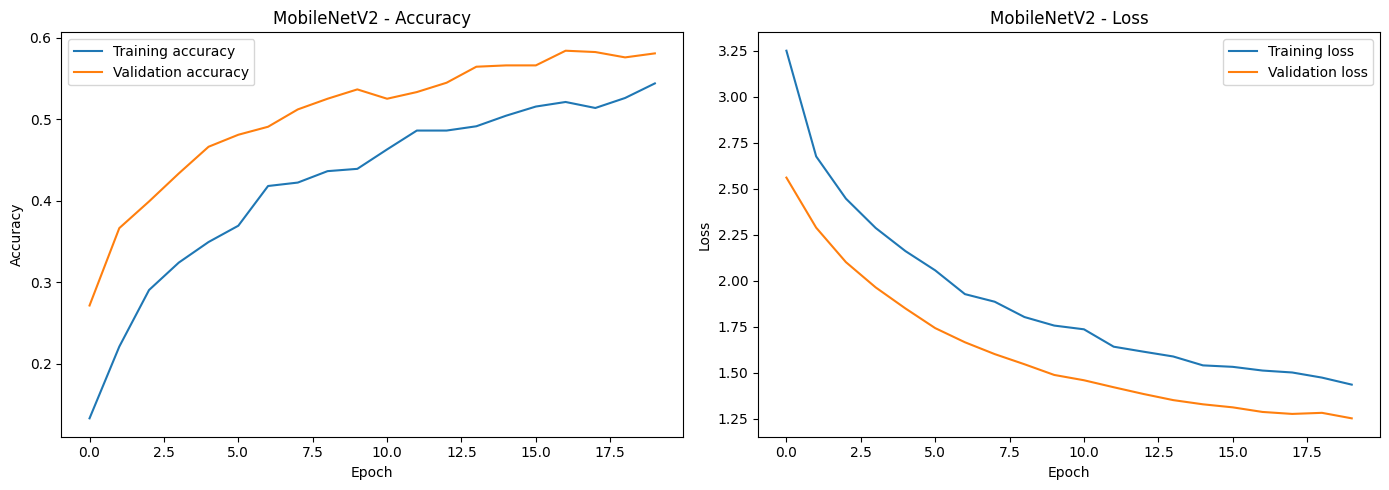

In [25]:
def plot_training_history(history, title):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation accuracy")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(mobilenet_history, "MobileNetV2")

## 21. Fine-tune the deeper MobileNetV2 layers

After training the new classification head, load the best checkpoint. Unfreeze only the last 30 layers of the MobileNetV2 feature extractor, while keeping Batch Normalization layers frozen. A smaller learning rate is used to make careful updates to pretrained weights.

In [26]:
mobilenet_model = tf.keras.models.load_model(
    MODEL_DIR / "best_mobilenetv2.keras"
)

base_model = next(
    layer for layer in mobilenet_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenet" in layer.name.lower()
)

base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

print("Trainable MobileNetV2 layers:",
      sum(layer.trainable for layer in base_model.layers),
      "of", len(base_model.layers))

Trainable MobileNetV2 layers: 19 of 154


## 22. Compile and fine-tune

Fine-tuning uses a learning rate of `1e-5`. The best fine-tuned checkpoint is saved according to validation loss.

In [27]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_mobilenetv2_finetuned.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

fine_tune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks
)

fine_tuning_minutes = (time.time() - start_time) / 60
print(f"Fine-tuning time: {fine_tuning_minutes:.2f} minutes")

Epoch 1/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5401 - loss: 1.4256
Epoch 1: val_loss improved from None to 1.17552, saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2_finetuned.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - accuracy: 0.5463 - loss: 1.4021 - val_accuracy: 0.5990 - val_loss: 1.1755 - learning_rate: 1.0000e-05
Epoch 2/15
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.5477 - loss: 1.3732
Epoch 2: val_loss improved from 1.17552 to 1.17483, saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_mobilenetv2_finetuned.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - accuracy: 0.5607 - loss: 1.3453 - val_accuracy: 0.5974 - val_loss: 1.1748 - learning_rate: 1.0000e-05
Epo

## 23. Plot fine-tuning history

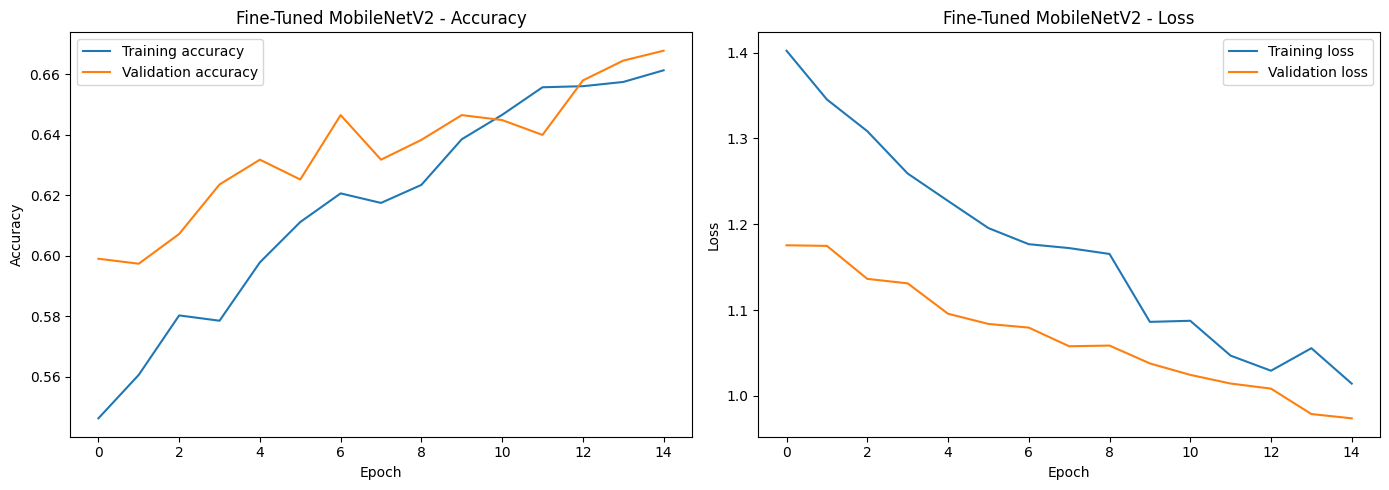

In [28]:
plot_training_history(fine_tune_history, "Fine-Tuned MobileNetV2")

## 24. Calculate class weights

The training labels may be imbalanced. Balanced class weights assign greater loss weight to less frequent classes. We calculate weights using the training set only.

In [29]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].values
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in enumerate(class_weights_array)
}

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"Class index {class_id}: {weight:.4f}")

Class weights:
Class index 0: 0.3658
Class index 1: 1.0690
Class index 2: 0.7425
Class index 3: 6.5263
Class index 4: 1.2400
Class index 5: 0.7898
Class index 6: 1.8235
Class index 7: 2.4800
Class index 8: 1.4762
Class index 9: 0.5188
Class index 10: 1.0783
Class index 11: 1.7465
Class index 12: 0.3272
Class index 13: 2.0000
Class index 14: 1.8788
Class index 15: 3.2632
Class index 16: 1.6316
Class index 17: 0.6019
Class index 18: 1.9683
Class index 19: 0.6049
Class index 20: 2.0000
Class index 21: 1.1481
Class index 22: 2.0000


## 25. Train the class-weighted MobileNetV2 model

Continue from the best fine-tuned MobileNetV2 checkpoint. Class weights are passed to `fit()` so errors on under-represented classes contribute more to the training loss. Validation loss determines the saved checkpoint.

Epoch 1/12
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6776 - loss: 1.0064
Epoch 1: val_loss improved from None to 1.02022, saving model to /content/drive/MyDrive/Ship_Classification/models/best_weighted_mobilenetv2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_weighted_mobilenetv2.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 23s 134ms/step - accuracy: 0.6651 - loss: 0.9981 - val_accuracy: 0.6530 - val_loss: 1.0202 - learning_rate: 5.0000e-06
Epoch 2/12
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.6484 - loss: 0.9865
Epoch 2: val_loss improved from 1.02022 to 1.00652, saving model to /content/drive/MyDrive/Ship_Classification/models/best_weighted_mobilenetv2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Ship_Classification/models/best_weighted_mobilenetv2.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 15s 122ms/step - accuracy: 0.6469 - loss: 0.9863 - val_accuracy: 0.6547 - val_loss: 1.0065 - learning_rate: 5.0000e-06
Epoch 3

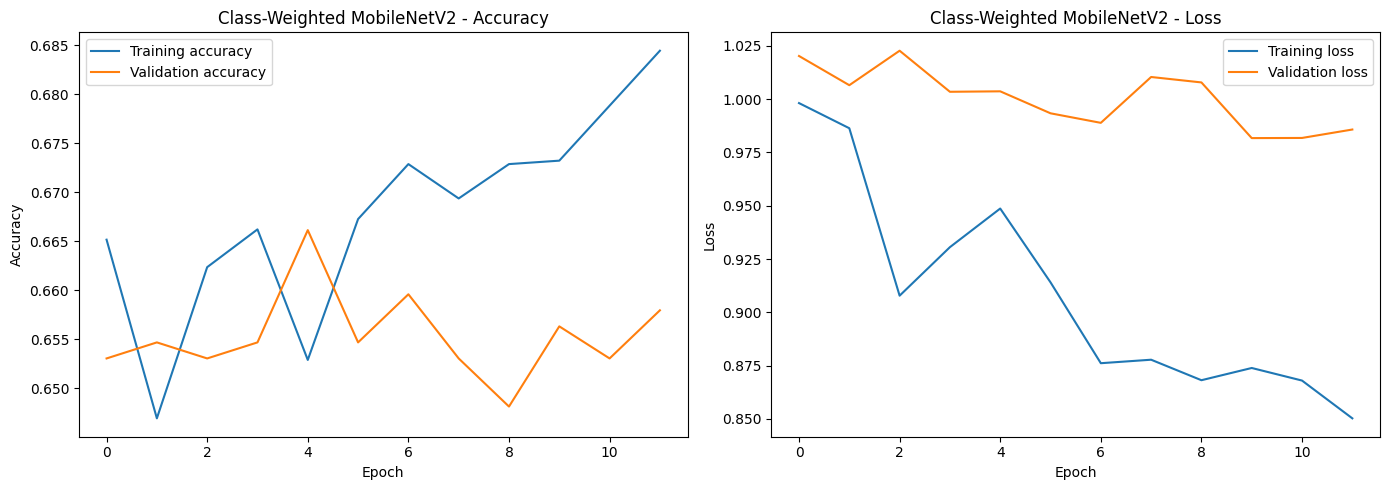

In [30]:
weighted_model = tf.keras.models.load_model(
    MODEL_DIR / "best_mobilenetv2_finetuned.keras"
)

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

weighted_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_weighted_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

weighted_history = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weights,
    callbacks=weighted_callbacks
)

plot_training_history(weighted_history, "Class-Weighted MobileNetV2")

## 26. Select and save the final model

The class-weighted model is retained as the selected model based on the validation-stage model-selection process. The test set is not used to choose between checkpoints.

The final saved model is `ship_classifier_selected.keras`.

In [31]:
selected_model = tf.keras.models.load_model(
    MODEL_DIR / "best_weighted_mobilenetv2.keras",
    compile=False
)

FINAL_MODEL_PATH = MODEL_DIR / "ship_classifier_selected.keras"
selected_model.save(FINAL_MODEL_PATH)

print("Selected class-weighted MobileNetV2 saved:")
print(FINAL_MODEL_PATH)

Selected class-weighted MobileNetV2 saved:
/content/drive/MyDrive/Ship_Classification/models/ship_classifier_selected.keras


## 27. Evaluate the selected model on the held-out test set

This is the final evaluation. Accuracy, weighted precision, weighted recall, weighted F1, and macro F1 are calculated on the test set. Macro F1 gives each class equal weight, while weighted F1 accounts for class support.

In [32]:
final_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

# Compile only to enable evaluate() with the selected loss and metric.
final_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

test_loss, test_accuracy = final_model.evaluate(test_ds, verbose=1)

y_prob = final_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_df["label"].values

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("\nFINAL TEST PERFORMANCE")
print("-----------------------------")
print(f"Test loss:       {test_loss:.4f}")
print(f"Accuracy:        {accuracy * 100:.2f}%")
print(f"Precision:       {precision * 100:.2f}%")
print(f"Recall:          {recall * 100:.2f}%")
print(f"Weighted F1:     {weighted_f1 * 100:.2f}%")
print(f"Macro F1:        {macro_f1 * 100:.2f}%")
print(f"Correct images:  {(y_true == y_pred).sum()} / {len(y_true)}")
print(f"Incorrect images:{(y_true != y_pred).sum()} / {len(y_true)}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.6748 - loss: 1.0607
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step

FINAL TEST PERFORMANCE
-----------------------------
Test loss:       1.0607
Accuracy:        67.48%
Precision:       69.59%
Recall:          67.48%
Weighted F1:     67.85%
Macro F1:        68.66%
Correct images:  413 / 612
Incorrect images:199 / 612


## 28. Per-class classification report

The report shows precision, recall, F1-score, and support for each numeric class label. Numeric labels are retained because a verified official folder-label-to-ship-name mapping has not been supplied in the dataset files used for this notebook.

In [33]:
class_names = [f"Class {index_to_class[i]}" for i in range(NUM_CLASSES)]

final_report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

final_report_df = pd.DataFrame(final_report).transpose()
display(final_report_df)

,precision,recall,f1-score,support
Class 0,0.919355,0.780822,0.844444,73.000000
Class 1,0.857143,0.960000,0.905660,25.000000
Class 10,0.894737,0.944444,0.918919,36.000000
Class 11,1.000000,1.000000,1.000000,4.000000
Class 12,0.681818,0.681818,0.681818,22.000000
Class 13,0.450000,0.529412,0.486486,34.000000
Class 14,0.714286,0.714286,0.714286,14.000000
Class 15,0.818182,0.818182,0.818182,11.000000
Class 16,0.857143,1.000000,0.923077,18.000000
Class 17,0.687500,0.431373,0.530120,51.000000


## 29. Confusion matrix

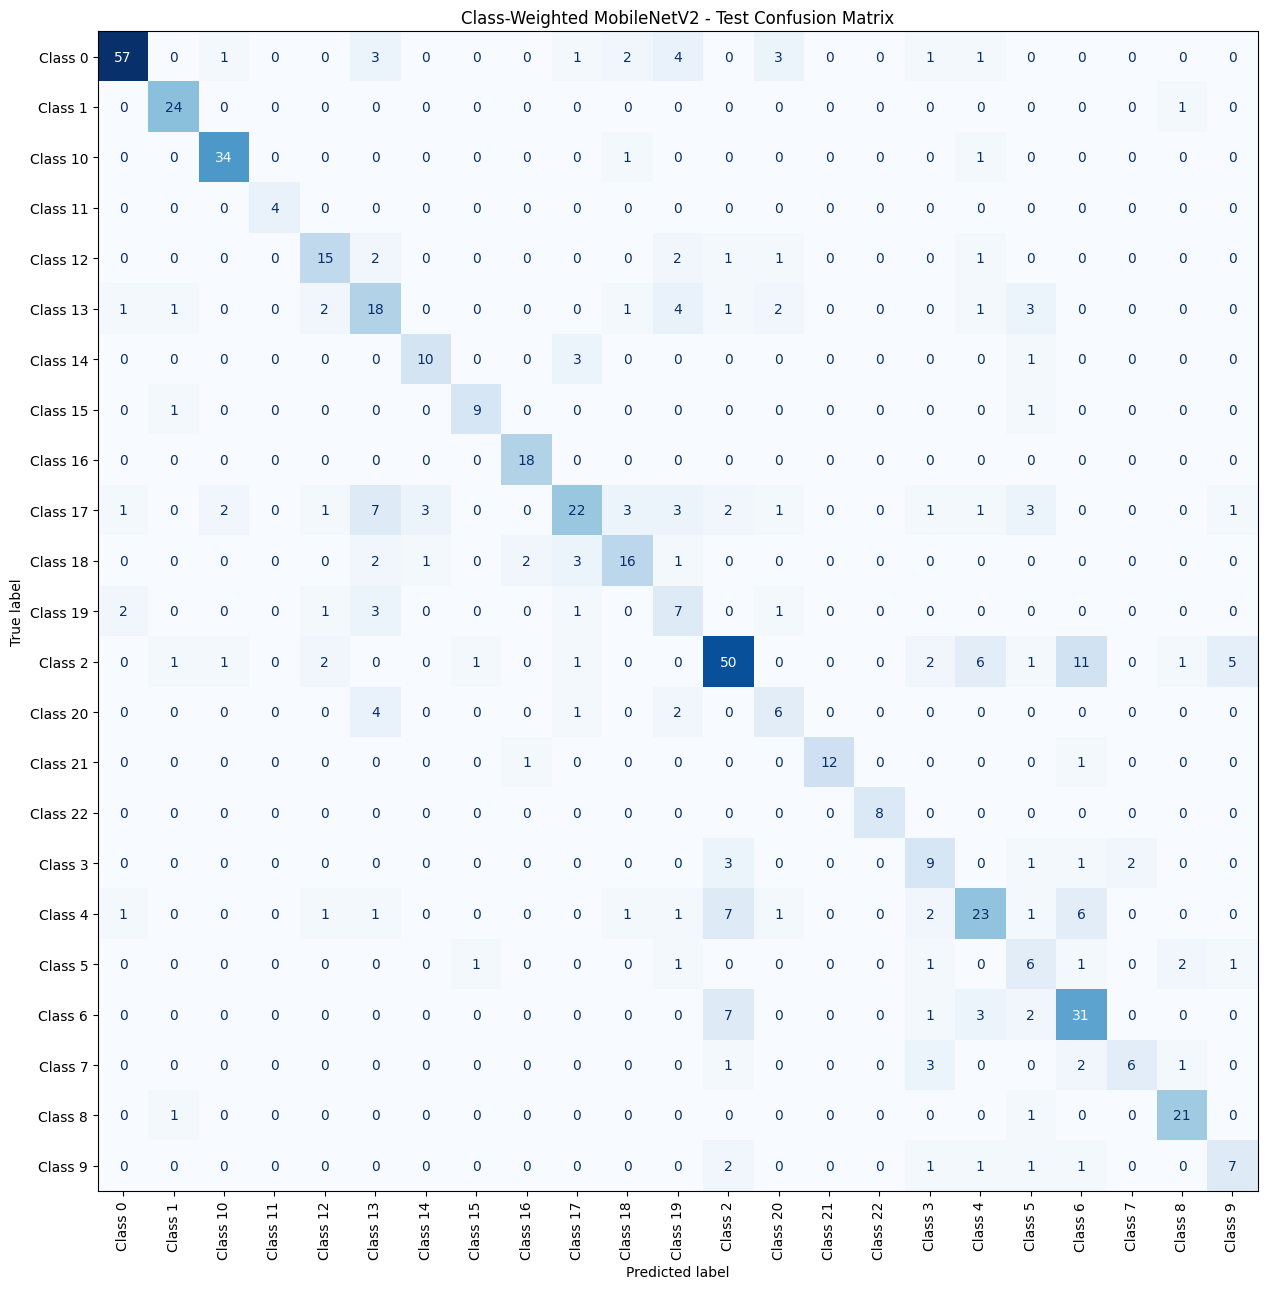

In [34]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(15, 13))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)
plt.title("Class-Weighted MobileNetV2 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 30. Save evaluation outputs

The classification report, confusion matrix, and individual test predictions are saved to Google Drive for project documentation.

In [35]:
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

final_report_df.to_csv(
    EVALUATION_DIR / "final_classification_report.csv"
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(EVALUATION_DIR / "final_confusion_matrix.csv")

predictions_df = test_df.copy()
predictions_df["predicted_label"] = y_pred
predictions_df["confidence"] = np.max(y_prob, axis=1)
predictions_df.to_csv(
    EVALUATION_DIR / "final_test_predictions.csv",
    index=False
)

print("Evaluation files saved in:", EVALUATION_DIR)

Evaluation files saved in: /content/drive/MyDrive/Ship_Classification/evaluation


## 31. Review some incorrect test predictions

This diagnostic step displays examples where the model's predicted label differs from the true test label. It helps identify visually similar categories and classes that need more data.

Test images: 612
Incorrect predictions: 199
Misclassification rate: 32.52%


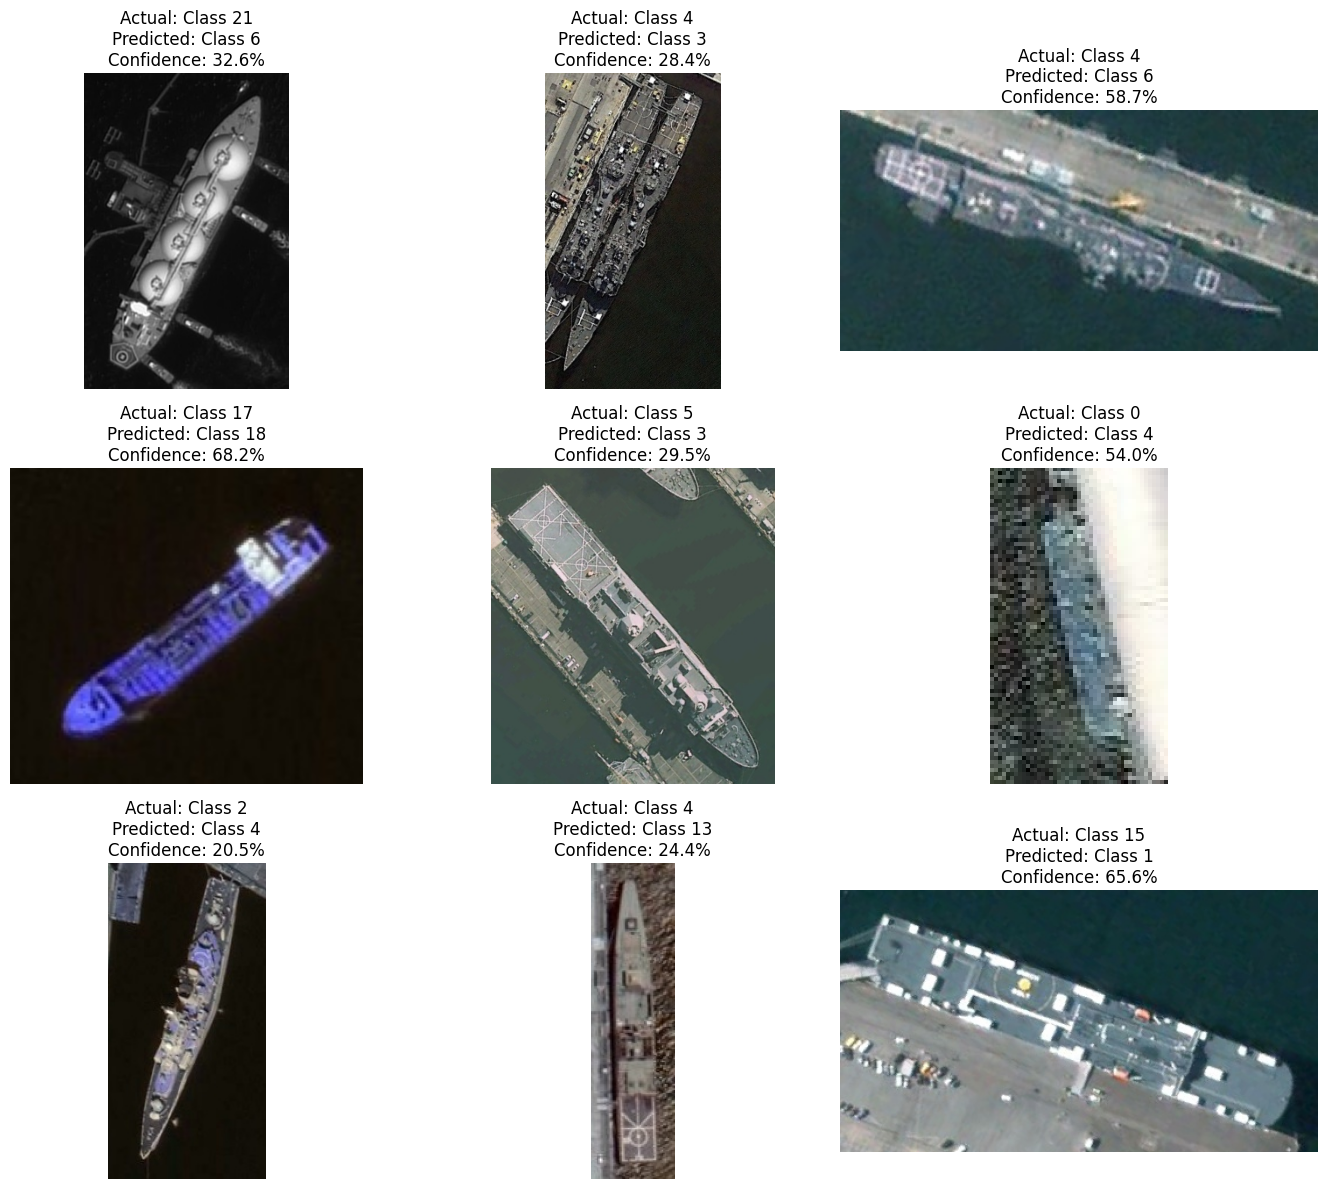

In [36]:
error_df = test_df.copy()
error_df["actual_class"] = [f"Class {index_to_class[int(i)]}" for i in y_true]
error_df["predicted_class"] = [f"Class {index_to_class[int(i)]}" for i in y_pred]
error_df["confidence"] = np.max(y_prob, axis=1)

misclassified_df = error_df[error_df["label"].values != y_pred].copy()

print("Test images:", len(test_df))
print("Incorrect predictions:", len(misclassified_df))
print("Misclassification rate:",
      f"{len(misclassified_df) / len(test_df) * 100:.2f}%")

if len(misclassified_df):
    sample_errors = misclassified_df.sample(
        n=min(9, len(misclassified_df)),
        random_state=SEED
    )

    plt.figure(figsize=(14, 12))
    for i, (_, row) in enumerate(sample_errors.iterrows(), start=1):
        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")
        plt.subplot(3, 3, i)
        plt.imshow(image)
        plt.title(
            f"Actual: {row['actual_class']}\n"
            f"Predicted: {row['predicted_class']}\n"
            f"Confidence: {row['confidence'] * 100:.1f}%"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions in this test set.")

## 32. Load the final model and class mapping for inference

This section prepares the saved model for individual image uploads. The reverse mapping converts the model's output index into the original numeric folder label.

In [37]:
final_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

with open(PROCESSED_DIR / "class_mapping.json", "r") as f:
    saved_mapping = json.load(f)

index_to_class = {
    int(index): str(folder_label)
    for index, folder_label in saved_mapping["index_to_class"].items()
}

print("Final MobileNetV2 loaded.")
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)
print("Number of classes:", len(index_to_class))

Final MobileNetV2 loaded.
Input shape: (None, 224, 224, 3)
Output shape: (None, 23)
Number of classes: 23


## 33. Define the single-image prediction function

The preprocessing used for an uploaded image must match the training pipeline: RGB conversion, resize to 224 × 224, and normalization to `[0, 1]`. The model's internal Rescaling layer then converts it to `[-1, 1]`.

The function displays the predicted numeric class, confidence, and top three predictions. Confidence is the model's softmax score, not a guarantee that the prediction is correct.

In [49]:
folder_label_to_name = {
    "0": "Non-ship",
    "1": "Aircraft Carrier",
    "2": "Destroyer",
    "3": "Landing Craft",
    "4": "Frigate",
    "5": "Amphibious Transport Dock",
    "6": "Cruiser",
    "7": "Tarawa-class Amphibious Assault Ship",
    "8": "Amphibious Assault Ship",
    "9": "Command Ship",
    "10": "Submarine",
    "11": "Medical Ship",
    "12": "Combat Boat",
    "13": "Auxiliary Ship",
    "14": "Container Ship",
    "15": "Car Carrier",
    "16": "Hovercraft",
    "17": "Bulk Carrier",
    "18": "Oil Tanker",
    "19": "Fishing Boat",
    "20": "Passenger Ship",
    "21": "Liquefied Gas Ship",
    "22": "Barge"
}

In [50]:
def predict_ship(image_path):

    # Load image
    image = Image.open(image_path).convert("RGB")
    display_image = image.copy()

    # Preprocess
    image = image.resize((224, 224))
    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    predictions = final_model.predict(image_array, verbose=0)[0]

    # Top 3 predictions
    top_indices = np.argsort(predictions)[-3:][::-1]

    # Best prediction
    predicted_index = int(top_indices[0])

    folder_label = index_to_class[predicted_index]

    ship_name = folder_label_to_name.get(
        folder_label,
        "Unknown Category"
    )

    confidence = predictions[predicted_index] * 100

    # Display main result
    print("\nSHIP CLASSIFICATION RESULTS")
    print("=" * 45)
    print("Model Output Index:", predicted_index)
    print("Dataset Class Number:", folder_label)
    print("Predicted Ship Type:", ship_name)
    print(f"Confidence: {confidence:.2f}%")

    # Display top 3
    print("\nTOP 3 PREDICTIONS")
    print("-" * 45)

    for rank, index in enumerate(top_indices, start=1):

        index = int(index)
        label = index_to_class[index]
        name = folder_label_to_name.get(label, "Unknown")
        score = predictions[index] * 100

        print(
            f"{rank}. Class {label} | {name} | {score:.2f}%"
        )

    # Display image
    plt.figure(figsize=(7, 6))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title(
        f"Class {folder_label}: {ship_name}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()


## 34. Upload a test image and predict its ship class

Upload one or more ship images. The model will display each image and return its predicted numeric folder label and top-three softmax scores.

For a meaningful evaluation, use images that were not used for training. The test-set metrics above remain the main quantitative evaluation.

Saving aerial-view-empty-cargo-ship-waiting-to-enter-the-port.webp to aerial-view-empty-cargo-ship-waiting-to-enter-the-port (5).webp

Image: aerial-view-empty-cargo-ship-waiting-to-enter-the-port (5).webp

SHIP CLASSIFICATION RESULTS
Model Output Index: 9
Dataset Class Number: 17
Predicted Ship Type: Bulk Carrier
Confidence: 92.49%

TOP 3 PREDICTIONS
---------------------------------------------
1. Class 17 | Bulk Carrier | 92.49%
2. Class 16 | Hovercraft | 3.18%
3. Class 14 | Container Ship | 2.59%


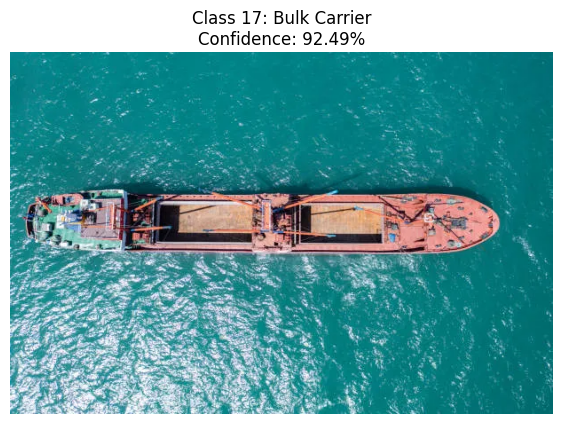

In [51]:
uploaded_images = files.upload()

for filename in uploaded_images.keys():
    print("\nImage:", filename)
    predict_ship(filename)

## 35. Project output files

The key outputs created by this notebook are:

- `models/ship_classifier_selected.keras` — selected class-weighted MobileNetV2 model
- `processed/train.csv` — training split metadata
- `processed/validation.csv` — validation split metadata
- `processed/test.csv` — test split metadata
- `processed/class_mapping.json` — numeric label mapping
- `evaluation/final_classification_report.csv` — per-class metrics
- `evaluation/final_confusion_matrix.csv` — confusion matrix
- `evaluation/final_test_predictions.csv` — test predictions and confidence scores

## 36. Conclusion

This project uses transfer learning with MobileNetV2 for fine-grained ship image classification. The pipeline includes image cleaning, stratified splitting, resizing and normalization, data augmentation, transfer learning, fine-tuning, class-weighted training, held-out test evaluation, and single-image inference.

**Limitations:** The model predicts one of the dataset's numeric folder classes. Human-readable ship-type names should only be added after verifying the official FGSC-23 label-to-folder mapping. A high softmax confidence score does not guarantee a correct prediction. Performance may also vary on images from different sensors, resolutions, viewpoints, or backgrounds.